# 00 · Data checks: from a messy table to a clean series frame

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/epjover/chronos2-in-practice/blob/main/notebooks/00_data_checks.ipynb)

Companion notebook for *Chronos-2 in Practice (1/7)*.

**What you will learn**

- Which quirks hide in a real energy dataset: daylight-saving offsets, missing values,
  empty columns, duplicated rows, Kelvin temperatures and a stray space in an id.
- How `c2p.data.validate_and_prepare()` turns such tables into clean series frames,
  and what it leaves alone on purpose.
- What gaps, sentinel zeros, dropped rows and outliers do to a Chronos-2 forecast,
  measured with a rolling-origin backtest instead of a single lucky example.
- Why a missing *row* hurts far more than a missing *value*.

Runtime: ~1 min on a laptop CPU (FAST_MODE: <1 min), plus a one-time
download of the dataset and the model.

In [1]:
# On Google Colab, clone the companion repo and install it (Colab's own PyTorch is kept).
# Locally, `uv sync` already installed everything and this cell does nothing.
import sys

if "google.colab" in sys.modules:
    !git clone --depth 1 https://github.com/epjover/chronos2-in-practice.git
    %cd chronos2-in-practice
    %pip install -q .
    import importlib

    importlib.invalidate_caches()

In [2]:
import time
from collections.abc import Callable, Sequence
from dataclasses import dataclass

import numpy as np
import pandas as pd
from chronos import Chronos2Pipeline
from huggingface_hub.utils import logging as hub_logging
from IPython.display import display
from transformers.utils import logging as transformers_logging

from c2p.config import SEED, get_device, get_paths, is_fast_mode, set_seed
from c2p.data import (
    drop_rows,
    inject_spike,
    load_energy_raw,
    load_weather_raw,
    mask_values,
    spain_energy_frame,
    spain_weather_frame,
    validate_and_prepare,
)
from c2p.eval import (
    ACTUAL_COL,
    COVERAGE_COLUMNS,
    CUTOFF_COL,
    MODEL_COL,
    SECONDS_COL,
    WINDOW_COL,
    BacktestConfig,
    backtest,
    evaluate,
    rolling_origin_windows,
    skill_table,
    summarize,
)
from c2p.models import Chronos2Forecaster, load_chronos2, parameter_count
from c2p.plotting import plot_benchmarks, plot_gap_grid, plot_scenarios, save_figure, set_style
from c2p.results import load_results, run_metadata, save_results
from c2p.schema import ID_COL, TIMESTAMP_COL, Forecaster

FAST_MODE = is_fast_mode(default=False)  # True: fewer windows/series, runs in a few minutes on CPU
PATHS = get_paths(fast_mode=FAST_MODE)
set_seed()
DEVICE = get_device()
set_style()
for key, value in run_metadata(device=DEVICE, fast_mode=FAST_MODE).items():
    print(f"{key:>20}: {value}")

              python: 3.11.17
              device: cuda
           fast_mode: False
                seed: 42
          run_at_utc: 2026-11-25 22:12
                 cpu: 12th Gen Intel(R) Core(TM) i9-12900K
     cores_available: 8
       torch_threads: 1
                 gpu: NVIDIA GeForce RTX 3070 (8 GiB)
 chronos-forecasting: 2.3.2
               torch: 2.14.1
              pandas: 3.1.0
               numpy: 2.4.6
                 fev: 0.10.0
       statsforecast: 2.0.1


## 1. A tour of the raw data

The two Kaggle files are read as published, untouched. Each check below prints one fact
computed from the data; nothing is repaired yet. The point is to *see* the problems
before a model silently absorbs them.

In [3]:
energy_raw = load_energy_raw()
weather_raw = load_weather_raw()
print(f"energy_dataset.csv:   {len(energy_raw):,} rows x {energy_raw.shape[1]} columns")
print(f"weather_features.csv: {len(weather_raw):,} rows x {weather_raw.shape[1]} columns")
energy_raw[["time", "total load actual", "total load forecast", "price actual"]].head(3)

energy_dataset.csv:   35,064 rows x 29 columns
weather_features.csv: 178,396 rows x 17 columns


,time,total load actual,total load forecast,price actual
0,2015-01-01 00:00:00+01:00,25385.0,26118.0,65.41
1,2015-01-01 01:00:00+01:00,24382.0,24934.0,64.92
2,2015-01-01 02:00:00+01:00,22734.0,23515.0,64.48


**Local time with daylight-saving offsets.** The `time` column is Madrid wall-clock
time written as text with its UTC offset, and the offset changes twice a year. Read
as local clock times, one spring day per year is an hour short and one autumn day an
hour long; in UTC the very same rows form a perfectly regular hourly grid.

In [4]:
offsets = energy_raw["time"].str[-6:].value_counts()
print("UTC offsets in the 'time' strings:", offsets.to_dict())

local_clock = pd.to_datetime(energy_raw["time"].str[:19])  # wall-clock time, offset dropped
hours_per_local_day = local_clock.dt.normalize().value_counts()
for n_hours in (23, 25):
    days = hours_per_local_day.index[hours_per_local_day == n_hours].sort_values()
    print(f"Local days with {n_hours} hours: {len(days)} ({', '.join(days.strftime('%Y-%m-%d'))})")

utc_steps = pd.to_datetime(energy_raw["time"], utc=True).diff().dropna().value_counts()
print("Steps between consecutive rows in UTC:", {str(step): n for step, n in utc_steps.items()})

UTC offsets in the 'time' strings: {'+02:00': 20664, '+01:00': 14400}
Local days with 23 hours: 4 (2015-03-29, 2016-03-27, 2017-03-26, 2018-03-25)
Local days with 25 hours: 4 (2015-10-25, 2016-10-30, 2017-10-29, 2018-10-28)
Steps between consecutive rows in UTC: {'0 days 01:00:00': 35063}


This is why a series frame stores **timezone-naive UTC** timestamps: no hour is
missing or repeated, so "one row per step" holds all year (and `predict_df` rejects
timezone-aware timestamps anyway). Calendar features that follow the local clock,
such as the hour of the day, are computed in local time later (article 3).

**Missing values and empty columns.** Some values are missing although their rows
exist, two columns are completely empty, and several generation columns only contain
zeros (a legitimate zero, not a missing reading).

In [5]:
load_missing = energy_raw["total load actual"].isna()
print(f"Missing 'total load actual' values: {load_missing.sum()} (rows exist, values are NaN)")
missing_by_year = energy_raw.loc[load_missing, "time"].str[:4].value_counts().sort_index()
print("  by year:", missing_by_year.to_dict())

values = energy_raw.drop(columns="time")
print("Columns that are entirely NaN:", values.columns[values.isna().all()].tolist())
all_zero = [col for col in values if values[col].notna().any() and values[col].dropna().eq(0).all()]
print("Columns whose observed values are all 0:", all_zero)

Missing 'total load actual' values: 36 (rows exist, values are NaN)
  by year: {'2015': 27, '2016': 5, '2017': 2, '2018': 2}
Columns that are entirely NaN: ['generation hydro pumped storage aggregated', 'forecast wind offshore eday ahead']
Columns whose observed values are all 0: ['generation fossil coal-derived gas', 'generation fossil oil shale', 'generation fossil peat', 'generation geothermal', 'generation marine', 'generation wind offshore']


**Weather: duplicated rows, Kelvin and a stray space.** The weather file has several
rows for the same city and hour, temperatures in Kelvin, and one city name with a
leading space, which silently breaks any filter or join on the city name.

In [6]:
keys = ["dt_iso", "city_name"]
print(f"Duplicated (time, city) rows: {weather_raw.duplicated(keys).sum():,}")
pairs = weather_raw[weather_raw.duplicated(keys, keep=False)].groupby(keys)
numeric = weather_raw.select_dtypes("number").columns.drop("weather_id")
n_numbers_differ = pairs[numeric].nunique().gt(1).any(axis=1).sum()
n_labels_differ = pairs["weather_main"].nunique().gt(1).sum()
print(
    f"  of {pairs.ngroups:,} duplicated pairs, {n_numbers_differ} differ in a measurement "
    f"and {n_labels_differ:,} in 'weather_main' (several conditions reported for one hour)"
)
temp = weather_raw["temp"]
print(f"'temp' ranges from {temp.min():.1f} to {temp.max():.1f}: Kelvin, not Celsius")
print("City names as stored:", weather_raw["city_name"].unique().tolist())

Duplicated (time, city) rows: 3,076
  of 2,798 duplicated pairs, 0 differ in a measurement and 2,777 in 'weather_main' (several conditions reported for one hour)
'temp' ranges from 262.2 to 315.6: Kelvin, not Celsius
City names as stored: ['Valencia', 'Madrid', 'Bilbao', ' Barcelona', 'Seville']


The weather is *observed*, not forecast. It can serve as a past covariate, but feeding
it as a known-future covariate would hand the model information it cannot have at
forecast time (article 3 comes back to this).

## 2. The checklist: `validate_and_prepare()`

The loaders `spain_energy_frame()` and `spain_weather_frame()` only reshape: they
rename columns, parse the offset strings into naive UTC, convert Kelvin to Celsius,
strip the city names and drop the empty columns. `validate_and_prepare()` then runs
the checklist, one small named step at a time:

1. check columns and dtypes, and work on a copy;
2. convert timestamps to naive UTC (offsets, tz-aware values or naive local times
   with `source_tz`);
3. turn sentinel values (e.g. `0` or `-999` meaning "no reading") into NaN;
4. resolve duplicated (series, timestamp) rows with an explicit policy;
5. reject timestamps that are off the `freq` grid instead of silently flooring them;
6. reindex every series to a regular grid, so missing rows become NaN rows;
7. optionally keep only the most recent rows;
8. flag series that are too short;
9. cast numbers to float64 and categorical columns to `category`.

It does **not** normalise, difference, detrend or impute: Chronos-2
standardises each series itself and masks NaN, so those steps would only lose
information, and imputed values would look like real observations.

In [7]:
energy, energy_report = validate_and_prepare(spain_energy_frame(), freq="h", target="load_actual")
print(energy_report)
print("Saved", save_results(energy_report.to_frame(), "00_data_report_energy", PATHS).name)

DataReport (freq='h', 1 series)
  rows in -> out:              35,064 -> 35,064
  duplicated rows resolved:    0
  sentinel values -> NaN:      0
  missing timestamps inserted: 0
  rows trimmed (max_length):   0
  missing values after prep:   load_actual=36, gen_biomass=19, gen_fossil_brown_coal_lignite=18, gen_fossil_coal_derived_gas=18, gen_fossil_gas=18, gen_fossil_hard_coal=18, gen_fossil_oil=19, gen_fossil_oil_shale=18, gen_fossil_peat=18, gen_geothermal=18, gen_hydro_pumped_storage_consumption=19, gen_hydro_run_of_river_and_poundage=19, gen_hydro_water_reservoir=18, gen_marine=19, gen_nuclear=17, gen_other=18, gen_other_renewable=18, gen_solar=18, gen_waste=19, gen_wind_offshore=18, gen_wind_onshore=18
  short series:                none
  note: Timestamps are timezone-naive and no source_tz was given: assumed to be UTC.
Saved 00_data_report_energy.csv


The energy table needs no structural repair: no duplicates and no missing timestamps.
The missing load values stay NaN, because Chronos-2 masks them. The report notes that
naive timestamps were taken as UTC, which is right here because the loader already
converted the offsets.

Many exports carry naive *local* times instead. Then pass the time zone with
`source_tz`: the repeated autumn hour is resolved from the row order. Feeding the
wall-clock times of section 1 this way must give the same UTC grid, hour for hour.

In [8]:
from_local_clock, _ = validate_and_prepare(
    spain_energy_frame().assign(timestamp=local_clock),
    freq="h",
    target="load_actual",
    source_tz="Europe/Madrid",
)
same_grid = from_local_clock[TIMESTAMP_COL].equals(energy[TIMESTAMP_COL])
print(f"Naive local times + source_tz='Europe/Madrid' give the same UTC timestamps: {same_grid}")

Naive local times + source_tz='Europe/Madrid' give the same UTC timestamps: True


The weather frame has five series (one per city). Duplicated rows are averaged
(`duplicates="mean"`; the measurements are identical anyway, and the categorical
`weather_main` keeps its first value).

In [9]:
weather, weather_report = validate_and_prepare(
    spain_weather_frame(),
    freq="h",
    target="temp_c",
    duplicates="mean",
    categorical=["weather_main"],
)
print(weather_report)
print("Series ids:", sorted(weather[ID_COL].unique()))
print("weather_main dtype:", weather["weather_main"].dtype)
print(f"temp_c ranges from {weather['temp_c'].min():.1f} to {weather['temp_c'].max():.1f} °C")
print("Saved", save_results(weather_report.to_frame(), "00_data_report_weather", PATHS).name)

DataReport (freq='h', 5 series)
  rows in -> out:              178,396 -> 175,320
  duplicated rows resolved:    3,076
  sentinel values -> NaN:      0
  missing timestamps inserted: 0
  rows trimmed (max_length):   0
  missing values after prep:   none
  short series:                none
  note: Timestamps are timezone-naive and no source_tz was given: assumed to be UTC.
Series ids: ['Barcelona', 'Bilbao', 'Madrid', 'Seville', 'Valencia']
weather_main dtype: category
temp_c ranges from -10.9 to 42.5 °C
Saved 00_data_report_weather.csv


## 3. Mini-demo: what messy data does to a forecast

Chronos-2 sees **positions, not dates**: the timestamps of the context only set the
timestamps of the forecast. So a NaN on a regular grid is a known unknown (the model
masks it), a `0` written where a reading is missing is a real-looking collapse of
demand, and a *removed row* silently shifts every older value by one step.

The demo measures this on the national load (`load_actual`) with the rolling-origin
backtest of `c2p.eval`: cutoffs nine days apart ending at the last timestamp (so the forecast
day walks through the week), a one-day horizon and a fixed context window, scored with fev-bench's metrics. Every scenario
starts from the same clean series, and its corruptions sit at the same seeded
positions inside the last week of each context:

| Scenario | What the model receives |
| --- | --- |
| `clean` | the prepared series |
| `gaps_nan` | gap values set to NaN on the regular grid (the right way) |
| `gaps_zero` | the same gaps filled with 0 (a sentinel treated as data) |
| `rows_dropped_freq` | the same gap rows removed, then `predict_df(..., freq="h")` |
| `spike` | one value multiplied (a measurement error) |
| `spike_as_nan` | the same value replaced by NaN (the checklist's fix) |

Only the target column goes to the model: every other column of the frame would
become a past covariate.

In [10]:
TARGET = "load_actual"
series = energy[[ID_COL, TIMESTAMP_COL, TARGET]]
config = BacktestConfig(
    prediction_length=24,
    n_windows=3 if FAST_MODE else 40,
    step=9 * 24,  # nine days between cutoffs: 40 windows across 2018, every weekday forecast
    freq="h",
    season_length=24,
    target=TARGET,
    max_context=2048,  # the same context length in every window
)
print(config)

BacktestConfig(prediction_length=24, n_windows=40, freq='h', season_length=24, step=216, quantile_levels=(0.01, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.99), target='load_actual', known_covariates=(), max_context=2048)


The corruptions reuse the seeded helpers of `c2p.data`. The random generator of a
window is seeded by its cutoff, so `mask_values` and `drop_rows` hit the same
hours in every gap scenario, and the spike scenarios share their position too.

In [11]:
LAST_WEEK = 7 * 24  # corruptions are placed in the last 7 days of each context
N_GAPS, GAP_LENGTH = 3, 6  # three gaps of 6 hours
SPIKE_HOURS, SPIKE_FACTOR = 48, 3.0  # one value tripled within the last 48 hours


def window_rng(context: pd.DataFrame) -> np.random.Generator:
    """Generator seeded by the window's cutoff: same positions in every scenario."""
    return np.random.default_rng([SEED, int(context[TIMESTAMP_COL].max().timestamp())])


def in_last_week(context: pd.DataFrame, corrupt: Callable) -> pd.DataFrame:
    """Apply ``corrupt(tail, rng)`` to the last week of the context only."""
    head, tail = context.iloc[:-LAST_WEEK], context.iloc[-LAST_WEEK:]
    return pd.concat([head, corrupt(tail, window_rng(context))], ignore_index=True)


def gaps(context: pd.DataFrame, fill: float) -> pd.DataFrame:
    gap_kwargs = {"n_gaps": N_GAPS, "gap_length": GAP_LENGTH, "column": TARGET, "fill": fill}
    return in_last_week(context, lambda tail, rng: mask_values(tail, rng=rng, **gap_kwargs))


def drop_gap_rows(context: pd.DataFrame) -> pd.DataFrame:
    gap_kwargs = {"n_gaps": N_GAPS, "gap_length": GAP_LENGTH, "column": TARGET}
    return in_last_week(context, lambda tail, rng: drop_rows(tail, rng=rng, **gap_kwargs))

In [12]:
def spike_position(context: pd.DataFrame) -> int:
    """Row position of the spike: one of the last SPIKE_HOURS rows."""
    return len(context) - 1 - int(window_rng(context).integers(SPIKE_HOURS))


def spike(context: pd.DataFrame) -> pd.DataFrame:
    return inject_spike(context, at=spike_position(context), factor=SPIKE_FACTOR, column=TARGET)


def spike_as_nan(context: pd.DataFrame) -> pd.DataFrame:
    """The checklist's fix for a measurement error: replace the value with NaN."""
    fixed = context.copy()
    fixed.iloc[spike_position(context), fixed.columns.get_loc(TARGET)] = np.nan
    return fixed

Two small wrappers plug the scenarios into the backtest. `Scenario` corrupts each
window's context right before the model sees it, while the harness keeps working on
the clean series, so cutoffs, actuals and metric scaling are identical everywhere.
`ChronosWithoutGridCheck` calls `predict_df` directly with `freq`, as a quick script
would. It exists on purpose: `Chronos2Forecaster` asserts a regular grid before every
call, so it would refuse the dropped-rows scenario.

In [13]:
@dataclass
class Scenario:
    """A Forecaster that corrupts each window's context before the model sees it."""

    name: str
    corrupt: Callable[[pd.DataFrame], pd.DataFrame]
    model: Forecaster

    def predict(self, context: pd.DataFrame, **kwargs: object) -> pd.DataFrame:
        return self.model.predict(self.corrupt(context), **kwargs)

In [14]:
@dataclass
class ChronosWithoutGridCheck:
    """Chronos-2 called directly with freq: missing rows are NOT detected."""

    pipeline: Chronos2Pipeline
    name: str = "chronos-2 (no grid check)"

    def predict(
        self,
        context: pd.DataFrame,
        *,
        prediction_length: int,
        quantile_levels: Sequence[float],
        freq: str,
        target: str,
        future_covariates: pd.DataFrame | None = None,
    ) -> pd.DataFrame:
        return self.pipeline.predict_df(
            context,
            target=target,
            prediction_length=prediction_length,
            quantile_levels=list(quantile_levels),
            freq=freq,
        )

In [15]:
hub_logging.set_verbosity_error()  # hide the Hub's "set an HF_TOKEN" hint
transformers_logging.disable_progress_bar()  # a saved progress bar would read "0%"

start = time.perf_counter()
pipeline = load_chronos2(device=DEVICE)
print(
    f"Chronos-2 loaded on {DEVICE} in {time.perf_counter() - start:.1f} s "
    f"({parameter_count(pipeline) / 1e6:.1f}M parameters)"
)
chronos = Chronos2Forecaster(pipeline)

Chronos-2 loaded on cuda in 1.0 s (119.5M parameters)


Before the backtest, look at a single context with its gap rows removed. Without
`freq`, Chronos-2 has to infer the frequency and refuses the irregular timestamps.
With `freq="h"` it accepts the same frame **without any warning**, and our
`Chronos2Forecaster` refuses it with an actionable message. Running the gappy frame
through `validate_and_prepare()` puts the rows back as NaN, which reproduces the
`gaps_nan` context.

In [16]:
context = rolling_origin_windows(series, config)[-1].context
gappy = drop_gap_rows(context)
print(f"Context rows: {len(context):,} on the regular grid, {len(gappy):,} after dropping the gaps")

horizon = config.prediction_length
try:
    pipeline.predict_df(gappy, target=TARGET, prediction_length=horizon)
except ValueError as error:
    print(f"predict_df without freq -> ValueError: {error}")
silent = pipeline.predict_df(gappy, target=TARGET, prediction_length=horizon, freq="h")
print(f"predict_df with freq='h' -> {len(silent)} forecast rows, no warning")
try:
    chronos.predict(
        gappy, prediction_length=horizon, quantile_levels=[0.5], freq="h", target=TARGET
    )
except ValueError as error:
    print(f"Chronos2Forecaster -> ValueError: {error}")

repaired, repair_report = validate_and_prepare(gappy, freq="h", target=TARGET)
print(
    f"validate_and_prepare re-inserted {repair_report.n_missing_timestamps} rows; "
    f"identical to the gaps_nan context: {repaired.equals(gaps(context, np.nan))}"
)

Context rows: 2,048 on the regular grid, 2,030 after dropping the gaps
predict_df without freq -> ValueError: Could not infer frequency for series ES
predict_df with freq='h' -> 24 forecast rows, no warning
Chronos2Forecaster -> ValueError: 1 series are not on a regular 'h' grid ('ES': expected 2018-12-25 00:00:00 after 2018-12-24 23:00:00, found 2018-12-25 06:00:00). Reindex every series to a regular grid with NaN for missing values (c2p.data.validate_and_prepare does this) before forecasting.
validate_and_prepare re-inserted 18 rows; identical to the gaps_nan context: True


Now the backtest: every scenario on every window, scored by `evaluate` against the
same clean actuals. WQL (weighted quantile loss) scores the whole predictive
distribution, MASE and WAPE the median; coverage is the share of actuals inside the
80% and 98% intervals. The cutoffs are nine days apart, so the 40 windows cover the
year and every weekday; a step of one week would forecast the same weekday every time,
and a deleted row costs more or less depending on which day it shifts. This is still a
comparison of the scenarios with each other, not a general accuracy estimate (article 2
does that). In FAST_MODE only the last few windows run, all in December: a smoke test
whose numbers (and the ranking the figure titles describe) can differ from the full run.

In [17]:
scenarios = [
    Scenario("clean", lambda context: context, chronos),
    Scenario("gaps_nan", lambda context: gaps(context, np.nan), chronos),
    Scenario("gaps_zero", lambda context: gaps(context, 0.0), chronos),
    Scenario("rows_dropped_freq", drop_gap_rows, ChronosWithoutGridCheck(pipeline)),
    Scenario("spike", spike, chronos),
    Scenario("spike_as_nan", spike_as_nan, chronos),
]
start = time.perf_counter()
forecasts = pd.concat([backtest(s, series, config) for s in scenarios], ignore_index=True)
elapsed = time.perf_counter() - start
print(f"{len(scenarios)} scenarios x {config.n_windows} windows: {elapsed:.0f} s")

metrics = evaluate(forecasts, series, config).rename(columns={MODEL_COL: "scenario"})
metric_columns = ["scenario", WINDOW_COL, CUTOFF_COL, "WQL", "MASE", "WAPE", *COVERAGE_COLUMNS]
print("Saved", save_results(metrics[metric_columns], "00_messy_data_scenarios", PATHS).name)

6 scenarios x 40 windows: 11 s
Saved 00_messy_data_scenarios.csv


The summary averages the windows of each scenario and compares it with `clean` in
two ways: the change of the mean WQL, and the typical per-window change (geometric
mean of the paired ratios, with a 95% bootstrap interval from `skill_table`), plus the
number of windows in which the scenario did worse than the clean data.

In [18]:
scenario_metrics = load_results("00_messy_data_scenarios", PATHS)
by_model = scenario_metrics.rename(columns={"scenario": MODEL_COL})
summary = summarize(by_model).set_index(MODEL_COL).loc[[s.name for s in scenarios]]
summary["WQL_change_pct"] = 100 * (summary["WQL"] / summary.loc["clean", "WQL"] - 1)

paired = skill_table(by_model, baseline="clean", metric="WQL").set_index(MODEL_COL)
gmean_ratio = 1 - paired[["skill", "ci_low", "ci_high"]]  # scenario / clean, typical window
summary["WQL_change_gmean_pct"] = 100 * (gmean_ratio["skill"] - 1)
summary["WQL_change_ci_low_pct"] = 100 * (gmean_ratio["ci_high"] - 1)
summary["WQL_change_ci_high_pct"] = 100 * (gmean_ratio["ci_low"] - 1)
wql = scenario_metrics.pivot_table(index=WINDOW_COL, columns="scenario", values="WQL")
summary["n_windows_worse"] = wql.gt(wql["clean"], axis=0).sum()

summary = summary.rename_axis("scenario").reset_index()
print("Saved", save_results(summary, "00_messy_data_summary", PATHS).name)

Saved 00_messy_data_summary.csv


In [19]:
summary = load_results("00_messy_data_summary", PATHS)
summary.drop(columns=["MASE_std", "WAPE_std", "coverage_80_std", "coverage_98_std"]).round(3)

,scenario,n_windows,WQL,WQL_std,MASE,WAPE,coverage_80,coverage_98,WQL_change_pct,WQL_change_gmean_pct,WQL_change_ci_low_pct,WQL_change_ci_high_pct,n_windows_worse
0,clean,40,0.040,0.044,0.541,0.047,0.682,0.929,0.000,0.000,0.000,0.000,0
1,gaps_nan,40,0.041,0.043,0.556,0.048,0.696,0.938,2.062,6.727,3.034,10.639,30
2,gaps_zero,40,0.046,0.041,0.636,0.055,0.749,0.996,14.174,31.789,13.626,57.455,27
3,rows_dropped_freq,40,0.082,0.035,1.195,0.103,0.732,0.970,104.130,207.998,126.343,314.231,32
4,spike,40,0.054,0.105,0.718,0.062,0.718,0.949,34.144,12.820,4.281,24.711,25
5,spike_as_nan,40,0.041,0.044,0.547,0.047,0.693,0.930,0.673,2.001,0.285,3.545,26


What to look for: NaN gaps and a spike replaced by NaN cost little (some information
is gone); zeros and an untreated spike cost more, because the model takes them
at face value; dropped rows are in a different league, because every value before
the gap now sits at the wrong time of day.

For the figure, one window stands for the rest: the window whose **clean** WQL is the
(lower) median across windows, a typical week for the model chosen without looking at
the corrupted scenarios. Its forecasts and the last week of each scenario's context
are saved first, and the figure is drawn from those files.

In [20]:
clean_wql = scenario_metrics[scenario_metrics["scenario"] == "clean"].set_index(WINDOW_COL)["WQL"]
example_window = int(clean_wql.sort_values().index[(len(clean_wql) - 1) // 2])
window = rolling_origin_windows(series, config)[example_window]
print(f"Example window: {example_window} (cutoff {window.cutoff})")

example = forecasts[forecasts[WINDOW_COL] == example_window].drop(columns=SECONDS_COL)
example = example.rename(columns={MODEL_COL: "scenario"})
print("Saved", save_results(example, "00_messy_data_example_forecasts", PATHS).name)

Example window: 37 (cutoff 2018-12-12 22:00:00)
Saved 00_messy_data_example_forecasts.csv


In [21]:
clean_values = window.context.set_index(TIMESTAMP_COL)[TARGET]
contexts = []
for scenario in scenarios:
    context = scenario.corrupt(window.context)
    context = context[context[TIMESTAMP_COL] > window.cutoff - pd.Timedelta(hours=LAST_WEEK)]
    values = context.set_index(TIMESTAMP_COL)[TARGET]
    changed = ~np.isclose(values, clean_values.reindex(values.index), equal_nan=True)
    contexts.append(context.assign(scenario=scenario.name, changed=changed))
columns = ["scenario", ID_COL, TIMESTAMP_COL, TARGET, "changed"]
example_context = pd.concat(contexts, ignore_index=True)[columns]
print("Saved", save_results(example_context, "00_messy_data_example_context", PATHS).name)

Saved 00_messy_data_example_context.csv


Each panel shows the last week of context the model received (gray spans: missing
values or missing rows; red dot: the spike), the forecast with its 80% and 98%
intervals, and what really happened. Panels have their own y scale, so that the
zeros and the spike do not flatten the others.

In [22]:
example_forecasts = load_results("00_messy_data_example_forecasts", PATHS)
example_context = load_results("00_messy_data_example_context", PATHS)
window_wql = scenario_metrics[scenario_metrics[WINDOW_COL] == example_forecasts[WINDOW_COL].iloc[0]]
window_wql = window_wql.set_index("scenario")["WQL"]
LABELS = {
    "clean": "Clean",
    "gaps_nan": "Gaps as NaN",
    "gaps_zero": "Gaps as 0",
    "rows_dropped_freq": "Rows dropped, freq='h'",
    "spike": f"Spike (x{SPIKE_FACTOR:g})",
    "spike_as_nan": "Spike set to NaN",
}
shown_scenarios = ["clean", "gaps_nan", "gaps_zero", "rows_dropped_freq", "spike"]
panels = {
    LABELS[name]: (
        example_context[example_context["scenario"] == name],
        example_forecasts[example_forecasts["scenario"] == name],
    )
    for name in shown_scenarios
}
spike_rows = example_context[(example_context["scenario"] == "spike") & example_context["changed"]]
is_clean = example_forecasts["scenario"] == "clean"
actuals = example_forecasts[is_clean].rename(columns={ACTUAL_COL: TARGET})

Saved 00_messy_data_scenarios.png


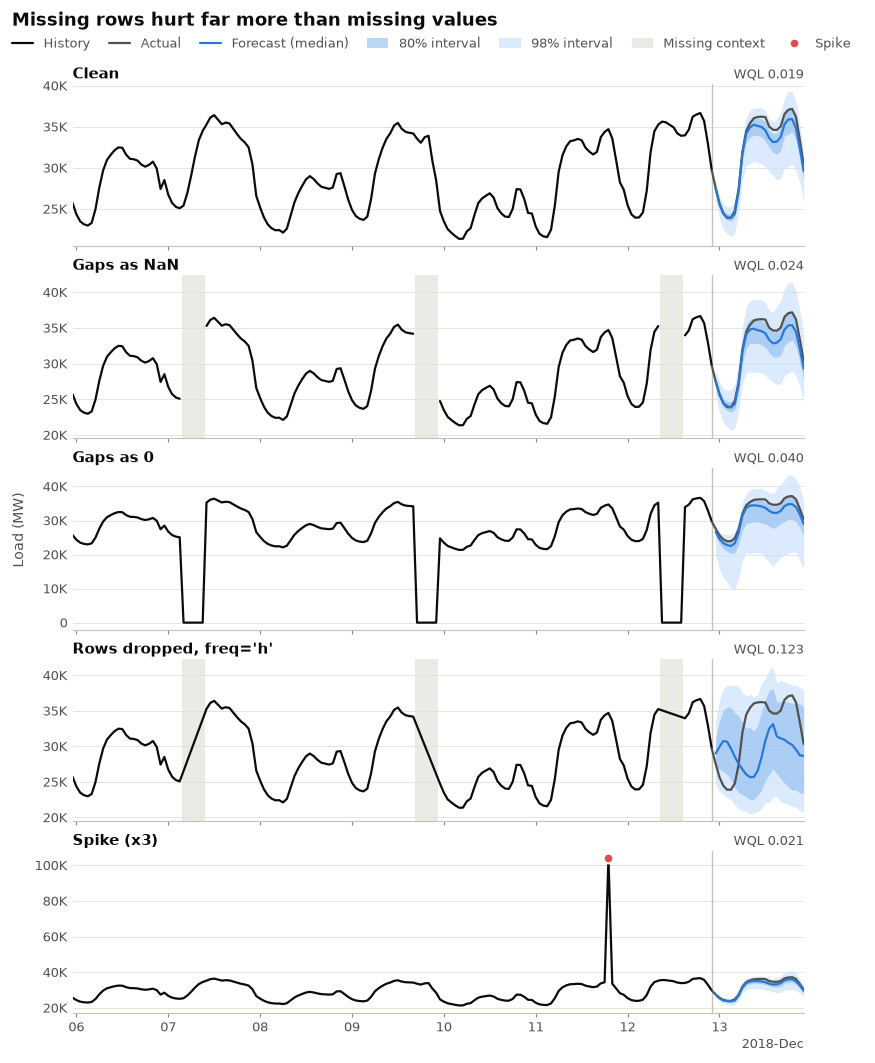

In [23]:
fig = plot_scenarios(
    panels,
    actuals=actuals,
    target=TARGET,
    history=LAST_WEEK,
    freq="h",
    sharey=False,
    spikes={LABELS["spike"]: spike_rows[TIMESTAMP_COL].tolist()},
    notes={LABELS[name]: f"WQL {window_wql[name]:.3f}" for name in shown_scenarios},
    title="Missing rows hurt far more than missing values",
    ylabel="Load (MW)",
)
display(fig)
print("Saved", save_figure(fig, "00_messy_data_scenarios", PATHS.figures)[0].name)

The same comparison over all windows, against clean data (the zero line is the clean
level): the change of the mean WQL, and the change in a typical window.

Saved 00_messy_data_summary.png


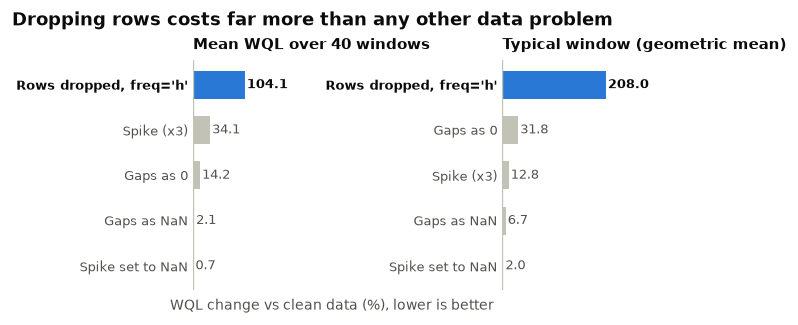

In [24]:
summary = load_results("00_messy_data_summary", PATHS)
measures = {
    "WQL_change_pct": f"Mean WQL over {summary['n_windows'].iloc[0]} windows",
    "WQL_change_gmean_pct": "Typical window (geometric mean)",
}
changes = summary[summary["scenario"] != "clean"].melt(
    id_vars="scenario", value_vars=list(measures), var_name="measure", value_name="change"
)
changes["model"] = changes["scenario"].map(LABELS)
changes["benchmark"] = changes["measure"].map(measures)
fig = plot_benchmarks(
    changes,
    value="change",
    highlight=LABELS["rows_dropped_freq"],
    xlabel="WQL change vs clean data (%), lower is better",
    title="Dropping rows costs far more than any other data problem",
)
display(fig)
print("Saved", save_figure(fig, "00_messy_data_summary", PATHS.figures)[0].name)

## 4. Seeing missing rows: the gap grid

Missing rows are invisible in a line chart, which connects the neighbouring
points. A day x hour grid makes them obvious. The slice below holds the two weeks up
to the example cutoff with the same dropped rows as the `rows_dropped_freq` scenario,
before and after `validate_and_prepare()`; the slice is saved first and the figure
drawn from the file.

In [25]:
example_cutoff = example_forecasts[CUTOFF_COL].iloc[0]
slice_start = (example_cutoff - pd.Timedelta(days=13)).normalize()
two_weeks = series[series[TIMESTAMP_COL].between(slice_start, example_cutoff)]
before = drop_gap_rows(two_weeks)  # same seed (cutoff) -> same gaps as in the backtest
after, _ = validate_and_prepare(before, freq="h", target=TARGET)
gap_grid = pd.concat([before.assign(frame="before"), after.assign(frame="after")])
print("Saved", save_results(gap_grid, "00_gap_grid", PATHS).name)

Saved 00_gap_grid.csv


Saved 00_gap_grid.png


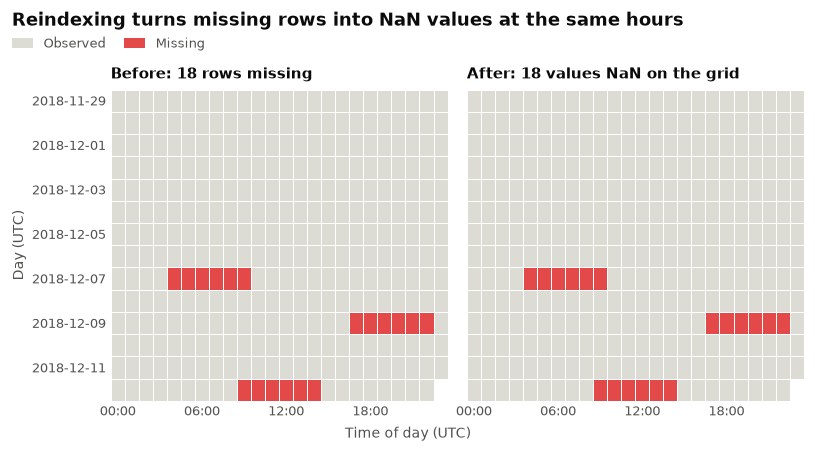

In [26]:
gap_grid = load_results("00_gap_grid", PATHS)
fig = plot_gap_grid(
    gap_grid[gap_grid["frame"] == "before"],
    gap_grid[gap_grid["frame"] == "after"],
    column=TARGET,
    title="Reindexing turns missing rows into NaN values at the same hours",
)
display(fig)
print("Saved", save_figure(fig, "00_gap_grid", PATHS.figures)[0].name)

## 5. Summary

The key numbers, read back from `results/`:

In [27]:
energy_report = load_results("00_data_report_energy", PATHS).set_index("metric")["value"]
weather_report = load_results("00_data_report_weather", PATHS).set_index("metric")["value"]
gap_grid = load_results("00_gap_grid", PATHS)
summary = load_results("00_messy_data_summary", PATHS)

print(
    f"Energy:  {int(energy_report['n_missing_timestamps'])} timestamps inserted, "
    f"{int(energy_report['n_duplicates'])} duplicates, "
    f"{int(energy_report['n_missing_values[load_actual]'])} load values left as NaN"
)
print(
    f"Weather: {int(weather_report['n_missing_timestamps'])} timestamps inserted, "
    f"{int(weather_report['n_duplicates']):,} duplicated rows averaged"
)
n_inserted = (gap_grid["frame"] == "after").sum() - (gap_grid["frame"] == "before").sum()
print(f"Gap demo: {n_inserted} dropped rows re-inserted as NaN by validate_and_prepare")
print(f"\nWQL vs clean over {summary['n_windows'].iloc[0]} windows:")
for row in summary[summary["scenario"] != "clean"].itertuples():
    interval = f"[{row.WQL_change_ci_low_pct:+.1f}, {row.WQL_change_ci_high_pct:+.1f}]"
    print(
        f"  {row.scenario:<18} mean {row.WQL_change_pct:+6.1f}% | typical window "
        f"{row.WQL_change_gmean_pct:+6.1f}% {interval} | "
        f"worse in {row.n_windows_worse}/{row.n_windows} windows"
    )

Energy:  0 timestamps inserted, 0 duplicates, 36 load values left as NaN
Weather: 0 timestamps inserted, 3,076 duplicated rows averaged
Gap demo: 18 dropped rows re-inserted as NaN by validate_and_prepare

WQL vs clean over 40 windows:
  gaps_nan           mean   +2.1% | typical window   +6.7% [+3.0, +10.6] | worse in 30/40 windows
  gaps_zero          mean  +14.2% | typical window  +31.8% [+13.6, +57.5] | worse in 27/40 windows
  rows_dropped_freq  mean +104.1% | typical window +208.0% [+126.3, +314.2] | worse in 32/40 windows
  spike              mean  +34.1% | typical window  +12.8% [+4.3, +24.7] | worse in 25/40 windows
  spike_as_nan       mean   +0.7% | typical window   +2.0% [+0.3, +3.5] | worse in 26/40 windows


**The checklist, in short**

- Store timestamps as timezone-naive **UTC**. Parse the offsets, or pass the source
  time zone for naive local times; never just drop the offset.
- One row per series and time step: **reindex to a regular grid**. A missing row
  shifts everything before it; a missing value is masked.
- Missing means **NaN**, never `0`, `-999` or an interpolated guess. Convert
  sentinels only in the columns where they really mean "no reading".
- Resolve duplicated (series, timestamp) rows with an explicit policy, and reject
  off-grid timestamps instead of flooring them.
- Replace values you *know* are measurement errors with NaN; keep real extremes.
- Do not normalise, difference, detrend or impute: Chronos-2 standardises each
  series and handles NaN itself.
- Observed weather is a past covariate, never a known-future one.
- Pass `freq` to `predict_df` only for data that has been through these checks:
  it switches off the library's own gap detection.

**Next:** [01_quickstart](01_quickstart.ipynb) loads Chronos-2 and makes a first
probabilistic forecast with a fan chart.